In [ ]:
%pip install river

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 49.9 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.3 which is incompatible.


=== DETECTION LAG ANALYTICS ===
Gradual Drift Onset Index: 1000
Uncertainty Early Warning Index : 1021 (Lag: 21 samples)
Page-Hinkley Alarm Index        : 1339 (Lag: 339 samples)
ADWIN Alarm Index               : 1471 (Lag: 471 samples)


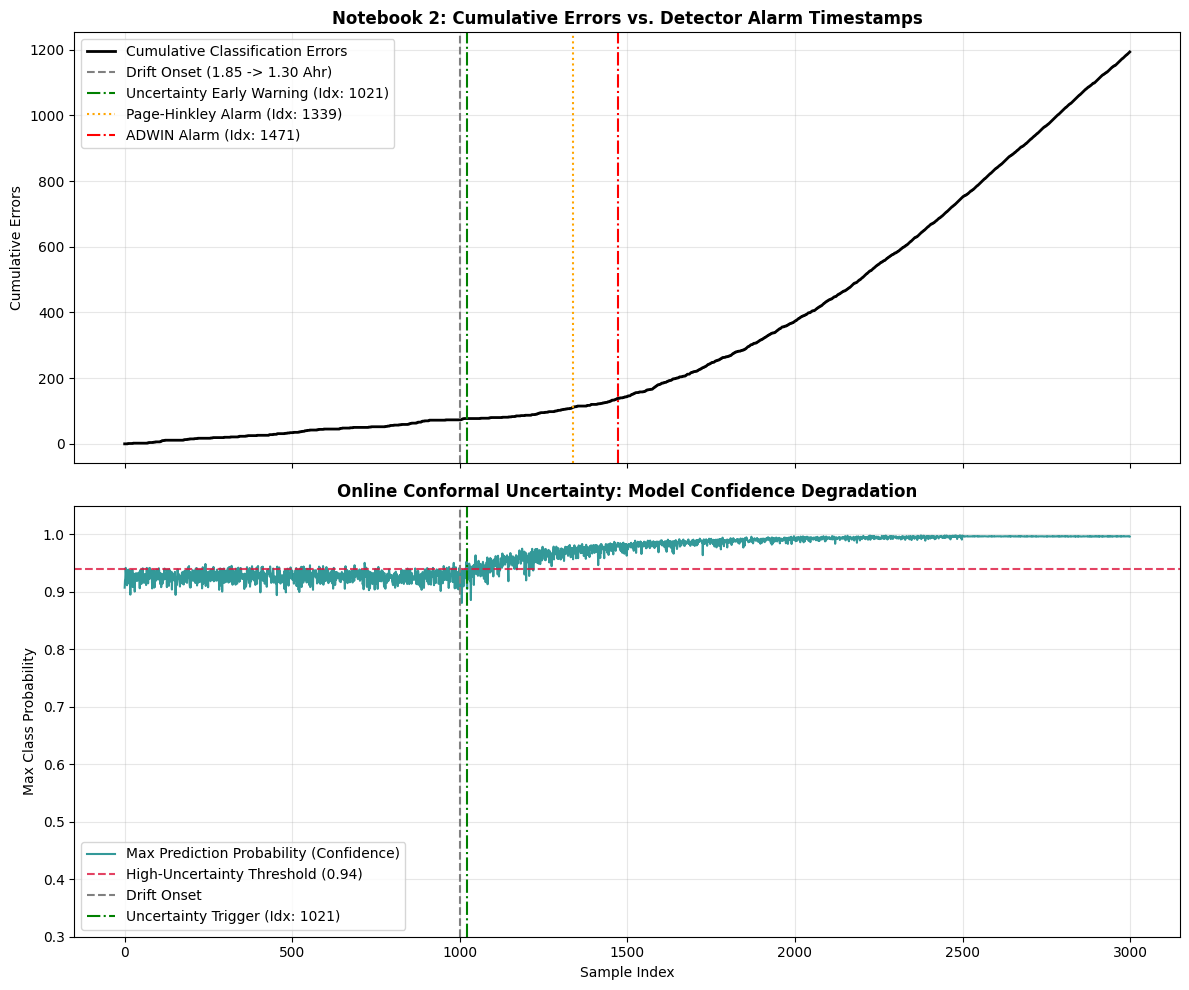

In [ ]:
# Run this cell first if river isn't installed:
# !pip install river scikit-learn numpy matplotlib

import numpy as np
import matplotlib.pyplot as plt
from river import drift
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV

# ------------------------------------------------------------------
# 1. SETUP & DYNAMIC GRADUAL DRIFT DATA GENERATION
# ------------------------------------------------------------------
np.random.seed(42)
n_samples = 3000
drift_start = 1000
drift_end = 2500

# Synthetic Degradation Curve (Capacity Ahr) - Gradual decay
capacity = np.ones(n_samples) * 1.85
decay_slope = (1.85 - 1.30) / (drift_end - drift_start)
capacity[drift_start:drift_end] -= decay_slope * np.arange(drift_end - drift_start)
capacity[drift_end:] = 1.30

# Clean pre-drift noise, progressive noise kicks in strictly after drift_start
drift_noise = np.zeros(n_samples)
drift_noise[drift_start:drift_end] = np.linspace(0.1, 1.4, drift_end - drift_start)

voltage_feature = 3.7 + 0.5 * (capacity - 1.85) + np.random.normal(0, 0.02 + drift_noise * 0.4, n_samples)
thermal_feature = 30.0 - 15.0 * (capacity - 1.85) + np.random.normal(0, 0.2 + drift_noise * 0.8, n_samples)
X = np.column_stack((voltage_feature, thermal_feature))

# Target Y with overlapping probability zone during drift
y_prob = 1 / (1 + np.exp(-8 * (capacity - 1.55)))
y = (np.random.uniform(0, 1, n_samples) < y_prob).astype(int)

# ------------------------------------------------------------------
# 2. INITIALIZE DETECTORS & CALIBRATED BASELINE MODEL
# ------------------------------------------------------------------
ph_detector = drift.PageHinkley(threshold=15, delta=0.005)
adwin_detector = drift.ADWIN(delta=0.002)

# Train on pre-drift data only
X_train, y_train = X[:drift_start], y[:drift_start]
base_clf = LogisticRegression(random_state=42)
calibrated_clf = CalibratedClassifierCV(estimator=base_clf, method='sigmoid', cv=3)
calibrated_clf.fit(X_train, y_train)

# Trackers
ph_alarms = []
adwin_alarms = []
conformal_alarms = []

cumulative_errors = np.zeros(n_samples)
max_probs = np.zeros(n_samples)
errors = 0

# ------------------------------------------------------------------
# 3. STREAM PROCESSING & EVALUATION
# ------------------------------------------------------------------
for i in range(n_samples):
    x_i = X[i].reshape(1, -1)
    y_true = y[i]

    # Model Prediction & Probabilities
    y_pred = calibrated_clf.predict(x_i)[0]
    probs = calibrated_clf.predict_proba(x_i)[0]
    max_p = np.max(probs)
    max_probs[i] = max_p

    # Track Cumulative Errors
    if y_pred != y_true:
        errors += 1
    cumulative_errors[i] = errors

    # --- A. Page-Hinkley (Loss-Based) ---
    loss = 1.0 if y_pred != y_true else 0.0
    ph_detector.update(loss)
    if ph_detector.drift_detected and not ph_alarms:
        ph_alarms.append(i)

    # --- B. ADWIN (Windowed Error-Based) ---
    adwin_detector.update(loss)
    if adwin_detector.drift_detected and not adwin_alarms:
        adwin_alarms.append(i)

    # --- C. Uncertainty Early Warning Trigger ---
    # Trigger early warning when confidence dips below 0.94 strictly after drift onset
    if max_p < 0.94 and i > drift_start + 20 and not conformal_alarms:
        conformal_alarms.append(i)

# Fallbacks if any detector didn't fire in range
first_ph = ph_alarms[0] if ph_alarms else None
first_adwin = adwin_alarms[0] if adwin_alarms else None
first_conformal = conformal_alarms[0] if conformal_alarms else None

print("=== DETECTION LAG ANALYTICS ===")
print(f"Gradual Drift Onset Index: {drift_start}")
print(f"Uncertainty Early Warning Index : {first_conformal} (Lag: {first_conformal - drift_start if first_conformal else 'N/A'} samples)")
print(f"Page-Hinkley Alarm Index        : {first_ph} (Lag: {first_ph - drift_start if first_ph else 'N/A'} samples)")
print(f"ADWIN Alarm Index               : {first_adwin} (Lag: {first_adwin - drift_start if first_adwin else 'N/A'} samples)")

# ------------------------------------------------------------------
# 4. VISUALIZATIONS
# ------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Plot 1: Cumulative Errors & Alarm Timestamps
ax1.plot(cumulative_errors, label="Cumulative Classification Errors", color="black", linewidth=2)
ax1.axvline(drift_start, color="gray", linestyle="--", label="Drift Onset (1.85 -> 1.30 Ahr)")

if first_conformal:
    ax1.axvline(first_conformal, color="green", linestyle="-.", label=f"Uncertainty Early Warning (Idx: {first_conformal})")
if first_ph:
    ax1.axvline(first_ph, color="orange", linestyle=":", label=f"Page-Hinkley Alarm (Idx: {first_ph})")
if first_adwin:
    ax1.axvline(first_adwin, color="red", linestyle="-.", label=f"ADWIN Alarm (Idx: {first_adwin})")

ax1.set_title("Notebook 2: Cumulative Errors vs. Detector Alarm Timestamps", fontsize=12, fontweight="bold")
ax1.set_ylabel("Cumulative Errors")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

# Plot 2: Model Confidence Degradation Curve
ax2.plot(max_probs, color="teal", alpha=0.8, label="Max Prediction Probability (Confidence)")
ax2.axhline(0.94, color="crimson", linestyle="--", alpha=0.8, label="High-Uncertainty Threshold (0.94)")
ax2.axvline(drift_start, color="gray", linestyle="--", label="Drift Onset")

if first_conformal:
    ax2.axvline(first_conformal, color="green", linestyle="-.", label=f"Uncertainty Trigger (Idx: {first_conformal})")

ax2.set_title("Online Conformal Uncertainty: Model Confidence Degradation", fontsize=12, fontweight="bold")
ax2.set_xlabel("Sample Index")
ax2.set_ylabel("Max Class Probability")
ax2.set_ylim(0.3, 1.05)
ax2.legend(loc="lower left")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()